# Week 4 — Denoising analysis

Goal: understand how the Week 3 denoiser (`denoise_image` in `utils.py`) behaves and
measure how good or bad it is, so we can improve it.

**Data**
- `data/qsd1_w4/*.jpg` — augmented queries (some have impulse noise, some a hue change, some nothing).
- `data/qsd1_w4/non_augmented/*.jpg` — the same images without augmentation (clean ground truth).
- `data/qsd1_w4/augmentations.pkl` — which augmentation each query received.

**How we judge a denoiser**
1. **Detection** — does it filter the images that really are noisy and leave the rest alone? (confusion matrix)
2. **Restoration** — after denoising, how close is the image to the clean one? (PSNR / SSIM vs clean, and the *gain* over doing nothing)
3. **Visual check** — side-by-side crops and error maps.

Any new method can be plugged into `evaluate_denoiser(...)` at the end and compared against the current one.

In [1]:
import sys
import pickle
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity

W4_DIR = Path.cwd() if (Path.cwd() / "utils.py").exists() else Path.cwd() / "w4"
sys.path.insert(0, str(W4_DIR))
from utils import denoise_image

DATA_DIR = W4_DIR.parent / "data"
NOISY_DIR = DATA_DIR / "qsd1_w4"
CLEAN_DIR = NOISY_DIR / "non_augmented"

# Same constants used inside utils.denoise_image
DIFF_THRESHOLD = 30      # a pixel is "isolated" if it differs > 30 from all 8 neighbours
FRACTION_THRESHOLD = 0.01  # image is flagged as noisy if > 1% of pixels are isolated

## 1. Load the noisy / clean pairs

Images are read with `IMREAD_IGNORE_ORIENTATION`: some JPGs carry EXIF rotation tags that differ
between the augmented and the clean copy (e.g. `00000`), which would make the pairs misaligned.

In [2]:
def read_bgr(path: Path) -> np.ndarray:
    img = cv2.imread(str(path), cv2.IMREAD_COLOR | cv2.IMREAD_IGNORE_ORIENTATION)
    if img is None:
        raise FileNotFoundError(path)
    return img


with open(NOISY_DIR / "augmentations.pkl", "rb") as f:
    augmentations = pickle.load(f)

ids = sorted(int(p.stem) for p in NOISY_DIR.glob("*.jpg"))
noisy = {i: read_bgr(NOISY_DIR / f"{i:05d}.jpg") for i in ids}
clean = {i: read_bgr(CLEAN_DIR / f"{i:05d}.jpg") for i in ids}

for i in ids:
    assert noisy[i].shape == clean[i].shape, f"{i}: {noisy[i].shape} vs {clean[i].shape}"

labels = pd.DataFrame({"id": ids, "augmentation": [augmentations[i] for i in ids]})
labels["is_impulse"] = labels["augmentation"].str.contains("ImpulseNoise")
print(labels["augmentation"].value_counts())

augmentation
None-MultiplyHue       12
None                    9
UnnamedImpulseNoise     9
Name: count, dtype: int64


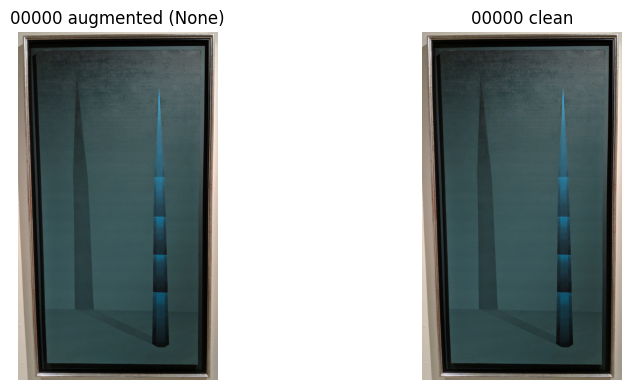

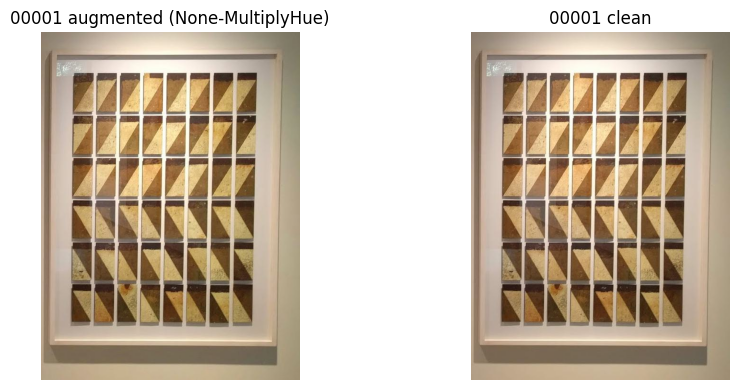

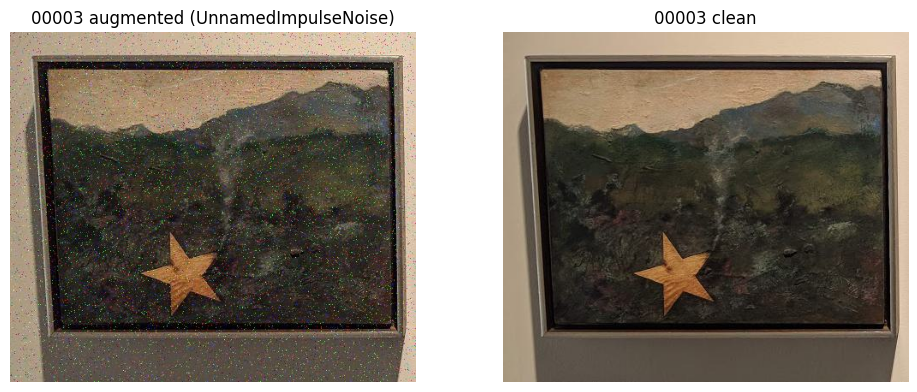

In [3]:
def show_row(images, titles, figsize=(18, 5)):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    for ax, img, title in zip(np.atleast_1d(axes), images, titles):
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


# One example of each augmentation type
for aug in labels["augmentation"].unique():
    i = labels.loc[labels["augmentation"] == aug, "id"].iloc[0]
    show_row([noisy[i], clean[i]], [f"{i:05d} augmented ({aug})", f"{i:05d} clean"], figsize=(10, 4))

## 2. How the current method works

`denoise_image` does two things:

1. **Detect** impulse (salt & pepper) noise: a pixel is *isolated* if its grayscale value differs by more
   than 30 from **all** 8 neighbours. If more than 1% of the pixels are isolated, the image is flagged.
2. **Filter**: flagged images get a 3×3 median blur; the rest are returned unchanged.

Below we recompute the isolated-pixel map so we can look inside the detector.

In [4]:
def isolated_map(image_bgr: np.ndarray, diff_threshold: int = DIFF_THRESHOLD) -> np.ndarray:
    """Boolean map of pixels that differ > diff_threshold from all 8 neighbours."""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY).astype(np.int16)
    h, w = gray.shape
    padded = np.pad(gray, 1, mode="edge")
    isolated = np.ones((h, w), dtype=bool)
    for dy in (-1, 0, 1):
        for dx in (-1, 0, 1):
            if dy == 0 and dx == 0:
                continue
            neighbor = padded[1 + dy: 1 + dy + h, 1 + dx: 1 + dx + w]
            isolated &= np.abs(gray - neighbor) > diff_threshold
    return isolated


def true_noise_map(noisy_bgr, clean_bgr, threshold=40):
    """Pixels that the augmentation actually changed a lot (only meaningful for impulse noise)."""
    diff = np.abs(noisy_bgr.astype(np.int16) - clean_bgr.astype(np.int16)).max(axis=2)
    return diff > threshold


def center_crop(img, size=200):
    h, w = img.shape[:2]
    y, x = (h - size) // 2, (w - size) // 2
    return img[y:y + size, x:x + size]

Image 00003 | augmentation: UnnamedImpulseNoise
  isolated-pixel fraction = 2.0592%  ->  flagged as noisy: True
  truly corrupted pixels  = 3.6788%


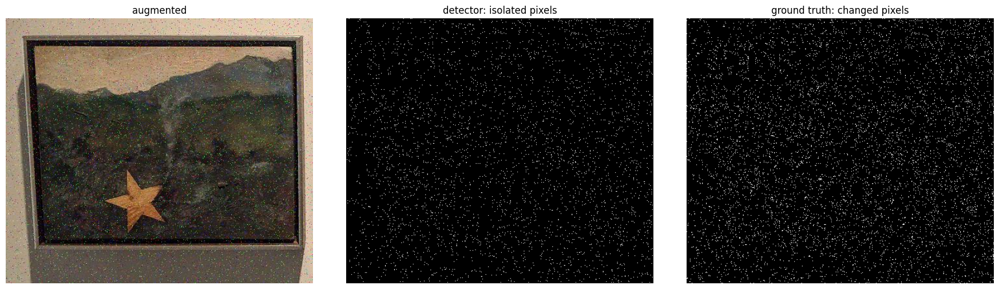

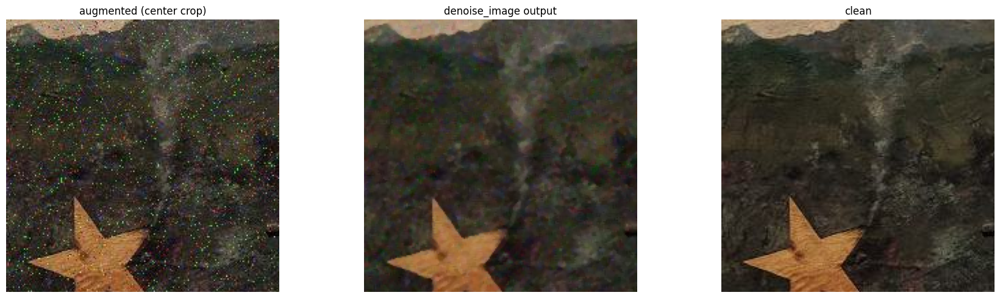

Image 00000 | augmentation: None
  isolated-pixel fraction = 0.0000%  ->  flagged as noisy: False
  truly corrupted pixels  = 0.0000%


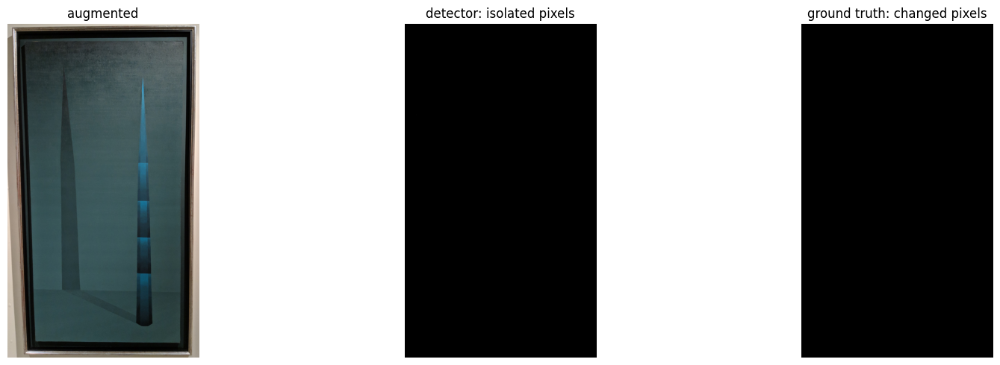

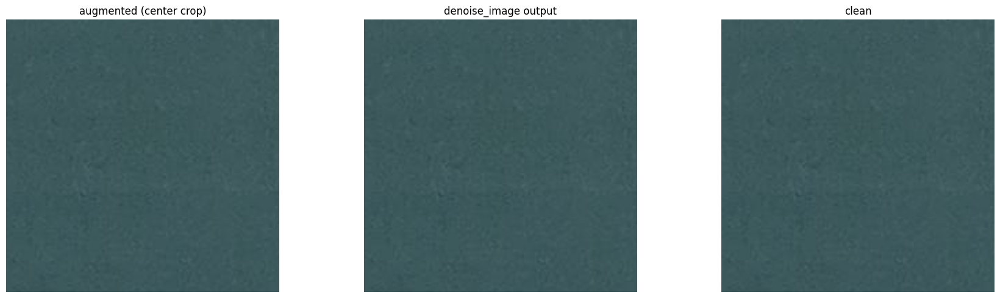

In [5]:
def explain_detector(i, crop=200):
    iso = isolated_map(noisy[i])
    truth = true_noise_map(noisy[i], clean[i])
    frac = iso.mean()
    flagged = frac > FRACTION_THRESHOLD
    denoised = denoise_image(noisy[i])

    print(f"Image {i:05d} | augmentation: {augmentations[i]}")
    print(f"  isolated-pixel fraction = {frac:.4%}  ->  flagged as noisy: {flagged}")
    print(f"  truly corrupted pixels  = {truth.mean():.4%}")

    show_row(
        [noisy[i], (iso * 255).astype(np.uint8), (truth * 255).astype(np.uint8)],
        ["augmented", "detector: isolated pixels", "ground truth: changed pixels"],
    )
    show_row(
        [center_crop(noisy[i], crop), center_crop(denoised, crop), center_crop(clean[i], crop)],
        ["augmented (center crop)", "denoise_image output", "clean"],
    )


impulse_ids = labels.loc[labels["is_impulse"], "id"].tolist()
other_ids = labels.loc[~labels["is_impulse"], "id"].tolist()

explain_detector(impulse_ids[0])
explain_detector(other_ids[0])

## 3. Detection quality

Is the 1% threshold separating noisy from non-noisy images? The bar chart shows the isolated-pixel
fraction per image (coloured by the real augmentation) with the decision threshold.

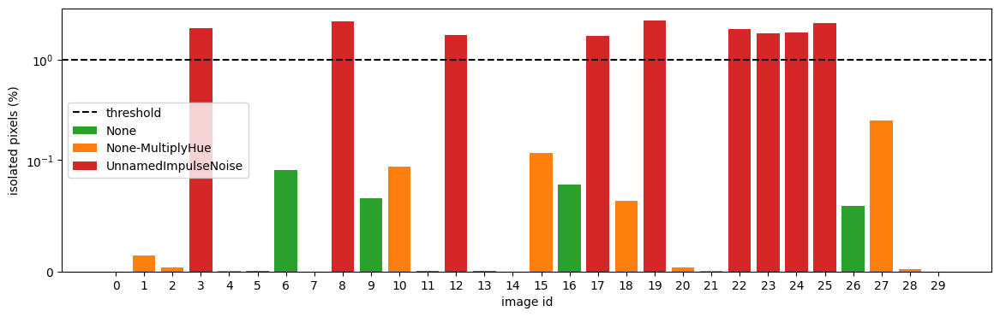

flagged by detector,False,True
really impulse noise,,
False,21,0
True,0,9


No detection errors.


In [6]:
labels["isolated_fraction"] = [isolated_map(noisy[i]).mean() for i in ids]
labels["flagged"] = labels["isolated_fraction"] > FRACTION_THRESHOLD

colors = {aug: c for aug, c in zip(labels["augmentation"].unique(), ["tab:green", "tab:orange", "tab:red", "tab:blue"])}
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(labels["id"].astype(str), labels["isolated_fraction"] * 100,
       color=[colors[a] for a in labels["augmentation"]])
ax.axhline(FRACTION_THRESHOLD * 100, color="black", ls="--", label="threshold")
for aug, c in colors.items():
    ax.bar(0, 0, color=c, label=aug)
ax.set_ylabel("isolated pixels (%)")
ax.set_yscale("symlog", linthresh=0.1)
ax.set_xlabel("image id")
ax.legend()
plt.show()

confusion = pd.crosstab(labels["is_impulse"], labels["flagged"],
                        rownames=["really impulse noise"], colnames=["flagged by detector"])
display(confusion)

errors = labels[labels["is_impulse"] != labels["flagged"]]
print("Misclassified images:" if len(errors) else "No detection errors.")
display(errors) if len(errors) else None

## 4. Restoration quality (PSNR / SSIM vs clean)

For every image we compare against the clean reference:
- **before**: augmented image vs clean (doing nothing)
- **after**: denoised image vs clean
- **gain** = after − before. Positive = the denoiser helped, negative = it damaged the image.

Notes:
- PSNR is computed in color, SSIM on grayscale (much faster on the large images).
- PSNR is capped at 60 dB: the `None` images are pixel-identical to the clean ones (infinite PSNR).
- A spatial filter cannot undo a **hue change**, so for `MultiplyHue` the best we can hope for is a gain of ~0
  (i.e. the denoiser should not touch it).

In [7]:
PSNR_CAP = 60.0  # identical images give infinite PSNR; cap so averages stay finite


def quality(img, ref):
    mse = np.mean((img.astype(np.float64) - ref.astype(np.float64)) ** 2)
    psnr = PSNR_CAP if mse == 0 else min(PSNR_CAP, 10 * np.log10(255 ** 2 / mse))
    ssim = structural_similarity(cv2.cvtColor(ref, cv2.COLOR_BGR2GRAY),
                                 cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), data_range=255)
    return psnr, ssim


def evaluate_denoiser(denoise_fn, name="method"):
    """Run denoise_fn on every query and score it against the clean images."""
    rows = []
    for i in ids:
        out = denoise_fn(noisy[i])
        psnr_b, ssim_b = quality(noisy[i], clean[i])
        psnr_a, ssim_a = quality(out, clean[i])
        rows.append({
            "method": name, "id": i, "augmentation": augmentations[i],
            "changed": not np.array_equal(out, noisy[i]),
            "psnr_before": psnr_b, "psnr_after": psnr_a, "psnr_gain": psnr_a - psnr_b,
            "ssim_before": ssim_b, "ssim_after": ssim_a, "ssim_gain": ssim_a - ssim_b,
        })
    return pd.DataFrame(rows)


def summarize(df):
    return (df.groupby(["method", "augmentation"])
              [["psnr_before", "psnr_after", "psnr_gain", "ssim_before", "ssim_after", "ssim_gain"]]
              .mean().round(3))


results = evaluate_denoiser(denoise_image, "week3 (detect + median 3x3)")
display(summarize(results))

psnr_before  psnr_after  \
method                      augmentation                                   
week3 (detect + median 3x3) None                      60.000      60.000   
                            None-MultiplyHue          38.279      38.279   
                            UnnamedImpulseNoise       23.351      30.251   

                                                 psnr_gain  ssim_before  \
method                      augmentation                                  
week3 (detect + median 3x3) None                       0.0        1.000   
                            None-MultiplyHue           0.0        0.986   
                            UnnamedImpulseNoise        6.9        0.468   

                                                 ssim_after  ssim_gain  
method                      augmentation                                
week3 (detect + median 3x3) None                      1.000      0.000  
                            None-MultiplyHue          0.986      0.000  
                            UnnamedImpulseNoise       0.847      0.379

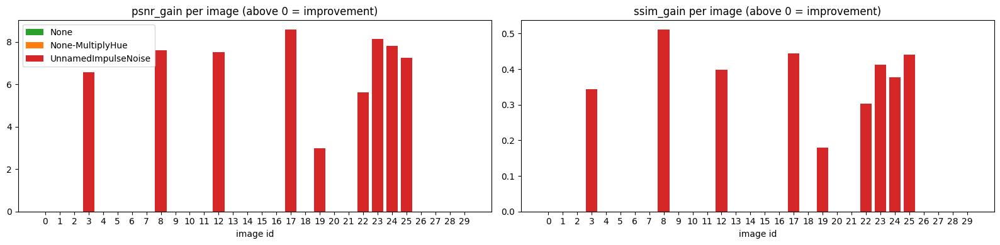

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, metric in zip(axes, ["psnr_gain", "ssim_gain"]):
    ax.bar(results["id"].astype(str), results[metric],
           color=[colors[a] for a in results["augmentation"]])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{metric} per image (above 0 = improvement)")
    ax.set_xlabel("image id")
for aug, c in colors.items():
    axes[0].bar(0, 0, color=c, label=aug)
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Visual check of the impulse-noise images

For each noisy image: augmented / denoised / clean crops, plus the absolute error of the denoised
image against the clean one (bright = remaining error). Remaining salt & pepper dots or blurred edges show up here.

00003  PSNR 23.29 -> 29.88 dB | SSIM 0.466 -> 0.810


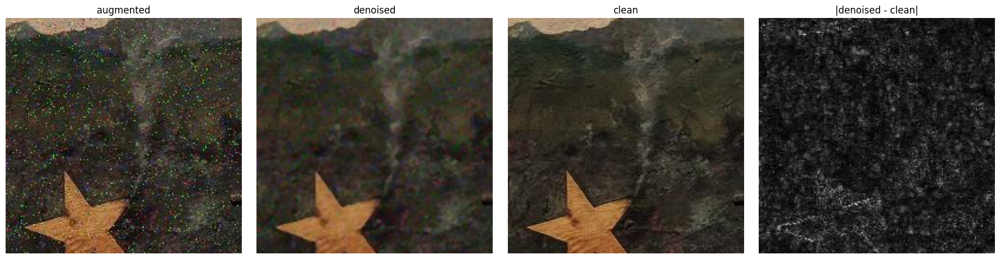

00008  PSNR 22.62 -> 30.23 dB | SSIM 0.339 -> 0.850


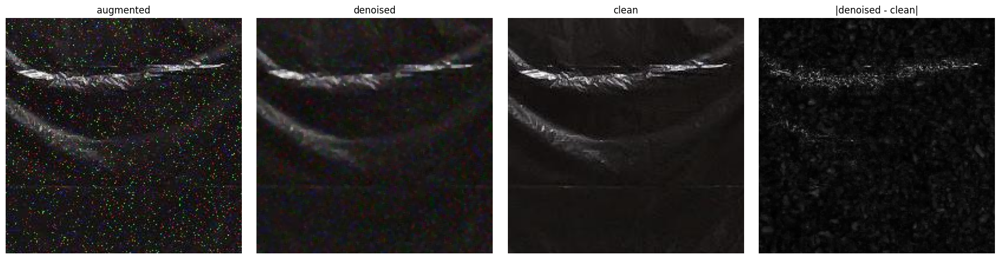

00012  PSNR 24.04 -> 31.57 dB | SSIM 0.434 -> 0.832


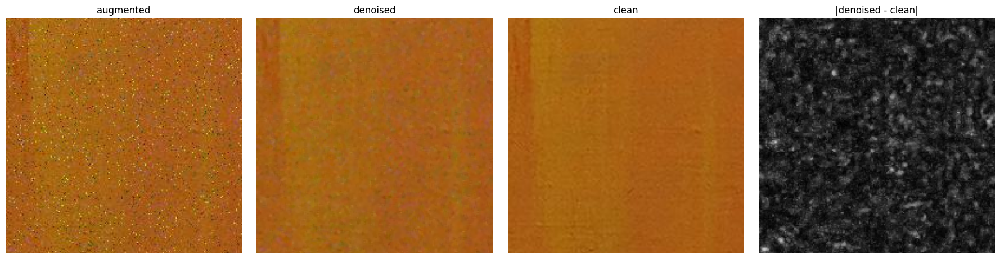

00017  PSNR 24.49 -> 33.08 dB | SSIM 0.406 -> 0.849


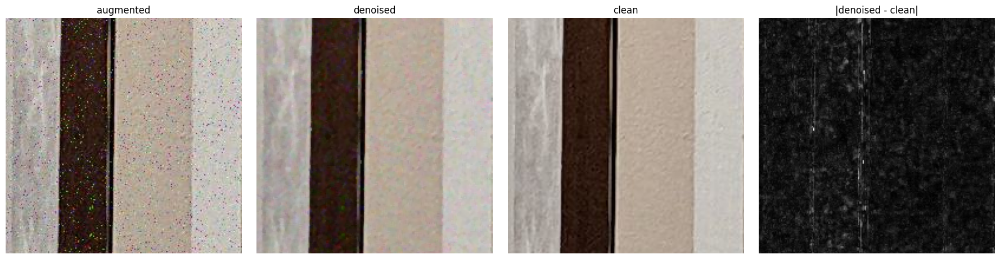

00019  PSNR 22.66 -> 25.64 dB | SSIM 0.715 -> 0.894


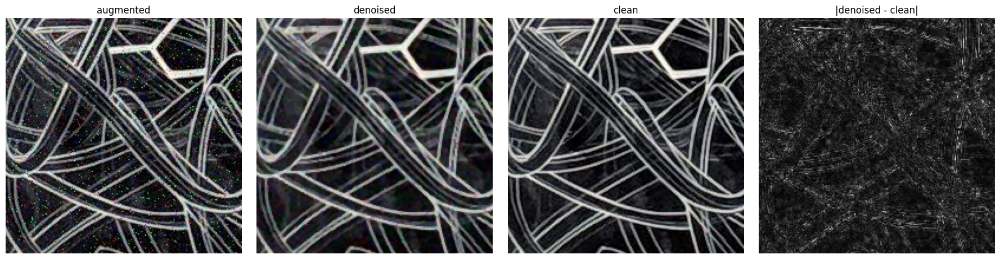

00022  PSNR 22.99 -> 28.60 dB | SSIM 0.518 -> 0.821


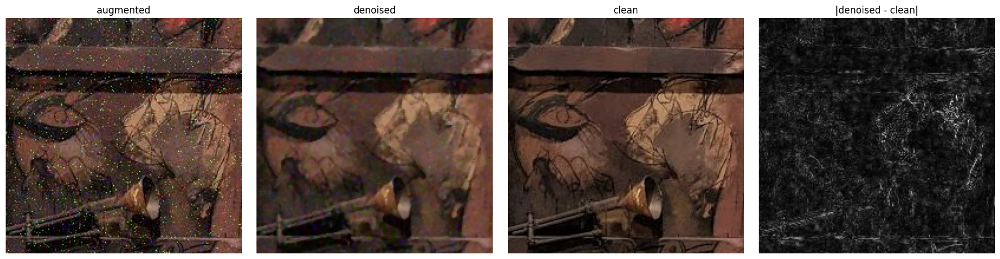

00023  PSNR 23.89 -> 32.02 dB | SSIM 0.451 -> 0.864


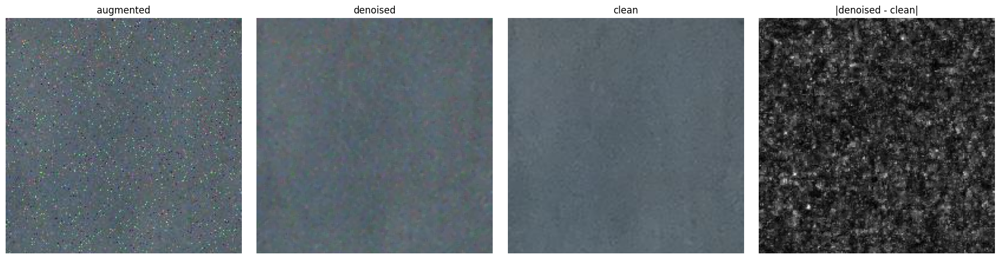

00024  PSNR 23.57 -> 31.38 dB | SSIM 0.486 -> 0.863


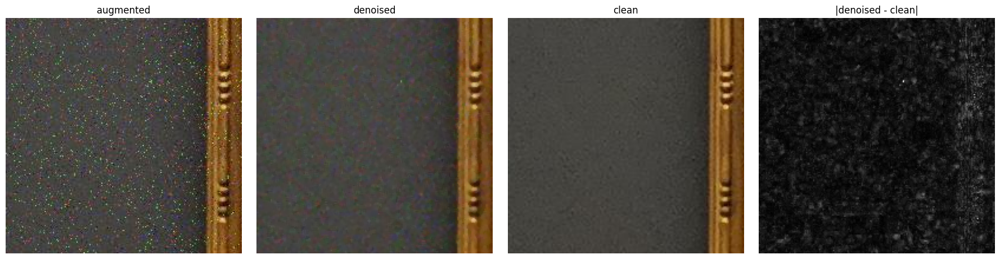

00025  PSNR 22.62 -> 29.88 dB | SSIM 0.398 -> 0.838


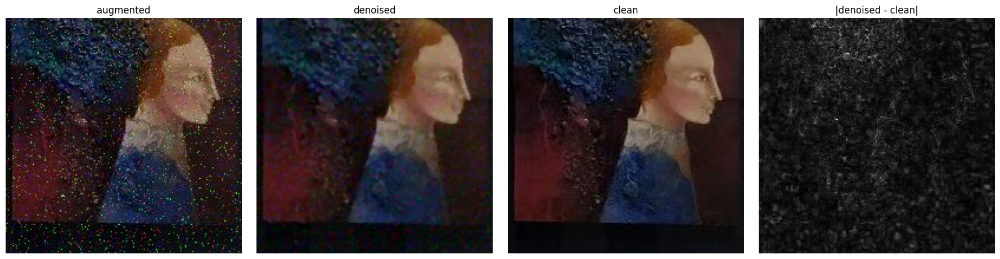

In [9]:
def error_map(img, ref):
    return np.abs(img.astype(np.int16) - ref.astype(np.int16)).max(axis=2).clip(0, 255).astype(np.uint8)


def show_restoration(i, denoise_fn=denoise_image, crop=200):
    out = denoise_fn(noisy[i])
    r = results.loc[results["id"] == i].iloc[0]
    print(f"{i:05d}  PSNR {r.psnr_before:.2f} -> {r.psnr_after:.2f} dB | SSIM {r.ssim_before:.3f} -> {r.ssim_after:.3f}")
    show_row(
        [center_crop(noisy[i], crop), center_crop(out, crop), center_crop(clean[i], crop),
         center_crop(error_map(out, clean[i]), crop)],
        ["augmented", "denoised", "clean", "|denoised - clean|"],
        figsize=(18, 4.5),
    )


for i in impulse_ids:
    show_restoration(i)

## 6. Comparing against other methods

Plug any `fn(image_bgr) -> image_bgr` into `evaluate_denoiser`. Baselines included:
- `identity` — do nothing (lower bound)
- `median 3x3 always` — no detector, shows what the detector buys us
- `oracle + median 3x3` — filter only the images we *know* are noisy (upper bound for the current filter)

Add new candidates to `candidates` as you develop them.

In [10]:
impulse_set = set(impulse_ids)
_oracle_lookup = {id(noisy[i]): i for i in ids}


def oracle(filter_fn):
    """Apply filter_fn only to images that are really impulse-noisy (uses the labels)."""
    def fn(img):
        return filter_fn(img) if _oracle_lookup.get(id(img)) in impulse_set else img.copy()
    return fn


candidates = {
    "identity": lambda img: img.copy(),
    "median 3x3 always": lambda img: cv2.medianBlur(img, 3),
    "oracle + median 3x3": oracle(lambda img: cv2.medianBlur(img, 3)),
    "week3 (detect + median 3x3)": denoise_image,
}

all_results = pd.concat(
    [results] + [evaluate_denoiser(fn, name) for name, fn in candidates.items() if name not in results["method"].unique()],
    ignore_index=True,
)

overall = all_results.groupby("method")[["psnr_after", "psnr_gain", "ssim_after", "ssim_gain"]].mean()
impulse_only = (all_results[all_results["augmentation"].str.contains("Impulse")]
                .groupby("method")[["psnr_after", "psnr_gain", "ssim_after", "ssim_gain"]].mean())

print("All images")
display(overall.sort_values("psnr_gain", ascending=False).round(3))
print("Impulse-noise images only")
display(impulse_only.sort_values("psnr_gain", ascending=False).round(3))

All images


,psnr_after,psnr_gain,ssim_after,ssim_gain
method,,,,
oracle + median 3x3,42.387,2.070,0.948,0.114
week3 (detect + median 3x3),42.387,2.070,0.948,0.114
identity,40.317,0.000,0.835,0.000
median 3x3 always,32.663,-7.654,0.904,0.069


Impulse-noise images only


,psnr_after,psnr_gain,ssim_after,ssim_gain
method,,,,
median 3x3 always,30.251,6.9,0.847,0.379
oracle + median 3x3,30.251,6.9,0.847,0.379
week3 (detect + median 3x3),30.251,6.9,0.847,0.379
identity,23.351,0.0,0.468,0.000


## 7. Takeaways / next steps

Fill in after running:
- Detector: how many misses / false alarms?
- Filter: how far is `week3` from the `oracle` (detection problem) and how much noise is left after median 3×3 (filter problem)?
- Ideas: adaptive / switching median (only replace detected impulse pixels), larger kernel or two passes for dense noise,
  per-channel detection, NL-means after median.